# 0. Overview
This notebook benchmarks multiple open-source ASR models across multiple datasets.
It measures:
- **Accuracy**: WER (raw + normalized), CER
- **Failure modes**: insertion/deletion/substitution rates
- **Performance**: mean latency + P95 latency (and optional cold vs warm)
- **Robustness**: tail error rates + dataset sensitivity
At the end, it produces **decision plots** to help pick a model.


# 1. Setup


## 1.1 Imports


In [1]:
import os
import time
import math
from pathlib import Path
from dataclasses import dataclass
from enum import Enum
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, HTML
from datasets import Audio, Dataset, load_dataset
import jiwer
from transformers.pipelines import pipeline

/home/hikmat/projects/nls-voice-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- Plot styling ---
sns.set_theme(style="whitegrid")            # modern replacement for set_style
plt.rcParams.update({"figure.figsize": (12, 6)})

In [3]:
print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available(), "torch_cuda:", torch.version.cuda)
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

torch: 2.9.1+cu128
cuda: True torch_cuda: 12.8
gpu: NVIDIA GeForce RTX 5060 Ti


# 2. Configuration


## 2.1 Enums


In [4]:
class SampleSize(int, Enum):
    """Sample size categories"""
    TINY = 10
    SMALL = 25
    MEDIUM = 50
    LARGE = 100
    XLARGE = 250
    XXLARGE = 500
    XXXLARGE = 1000


In [5]:
class Language(str, Enum):
    EN = "en"
    DE = "de"
    FR = "fr"
    ES = "es"
    IT = "it"
    PT = "pt"
    NL = "nl"
    PL = "pl"
    MULTI = "multi"

In [6]:
class ModelCapability(str, Enum):
    ENGLISH_ONLY = "english_only"
    MULTILINGUAL = "multilingual"

In [7]:
class DatasetGroup(str, Enum):
    CLEAN = "clean"
    NOISY = "noisy"
    CONVERSATIONAL = "conversational"
    FORMAL = "formal"
    MUSIC = "music"
    GENERAL = "general"

## 2.2 Global Configuration


In [8]:
@dataclass(frozen=True)
class GlobalConfig:
    # ---- Experiment scope ----
    allowed_languages: set[Language] | None = None
    allowed_groups: set[DatasetGroup] | None = None

    quick_test: bool = False
    quick_limit: int = 3

    sample_size: SampleSize = SampleSize.LARGE

    # ---- Paths / caching ----
    cache_dir_datasets: Path = Path("data/cached_datasets")
    cache_dir_models: Path | None = None   # None = default HF cache
    output_dir: Path = Path("data/results")

In [9]:
CONFIG = GlobalConfig(
    allowed_languages={Language.EN},
    sample_size=SampleSize.TINY,
)

In [10]:
print("=" * 80)
print("PREFERENCES")
print("=" * 80)

langs = (
    ", ".join(sorted(l.value for l in CONFIG.allowed_languages))
    if CONFIG.allowed_languages
    else "ALL"
)
groups = (
    ", ".join(sorted(g.value for g in CONFIG.allowed_groups))
    if CONFIG.allowed_groups
    else "ALL"
)

print(f"Languages: {langs}")
print(f"Dataset groups: {groups}")

print(f"Quick test: {CONFIG.quick_test}")
if CONFIG.quick_test:
    print(f"  Limit: {CONFIG.quick_limit}")

print(
    f"Sample size: {CONFIG.sample_size.name} "
    f"({CONFIG.sample_size.value} samples)"
)

print("\nDirectories:")
print(f"  Dataset cache: {CONFIG.cache_dir_datasets}")
print(f"  Model cache: {CONFIG.cache_dir_models or '~/.cache/huggingface (default)'}")
print(f"  Output: {CONFIG.output_dir}")

print("=" * 80)

PREFERENCES
Languages: en
Dataset groups: ALL
Quick test: False
Sample size: TINY (10 samples)

Directories:
  Dataset cache: data/cached_datasets
  Model cache: ~/.cache/huggingface (default)
  Output: data/results


# 3. Data layer (dataset configs + loading + caching)


## 3.1 DatasetConfig


In [11]:
@dataclass
class DatasetConfig:
    name: str
    hf_dataset_name: str
    hf_config: Optional[str] = None
    hf_split: str = "test"

    audio_column: str = "audio"
    text_column: str = "text"

    description: str = ""

    language: Language = Language.EN
    group: DatasetGroup = DatasetGroup.GENERAL

    use_streaming: bool = True
    sample_size: Optional[int] = None

## 3.2 Dataset loader + cache


In [12]:
def load_dataset_from_config(config: DatasetConfig) -> Dataset:
    """Load dataset from HuggingFace configuration with optional streaming support."""
    max_samples = config.sample_size
    print(f"📥 Loading {config.name} ({max_samples} samples)... ", end="", flush=True)

    if config.use_streaming:
        from itertools import islice

        dataset_stream = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=config.hf_split,
            streaming=True,
            trust_remote_code=True
        )
        dataset_stream = dataset_stream.shuffle(seed=42, buffer_size=1000)
        samples = list(islice(dataset_stream, max_samples))
        dataset = Dataset.from_list(samples)

        if "audio" in dataset.column_names:
            dataset = dataset.cast_column("audio", Audio())
    else:
        dataset = load_dataset(
            config.hf_dataset_name,
            config.hf_config,
            split=f"{config.hf_split}[:{max_samples}]",
            trust_remote_code=True
        )

    # Normalize column names
    if config.text_column != "text" and config.text_column in dataset.column_names:
        dataset = dataset.rename_column(config.text_column, "text")
    if config.audio_column != "audio" and config.audio_column in dataset.column_names:
        dataset = dataset.rename_column(config.audio_column, "audio")

    # Keep only what we need
    keep = ["audio", "text"]
    to_remove = [c for c in dataset.column_names if c not in keep]
    if to_remove:
        dataset = dataset.remove_columns(to_remove)

    print(f"✓ ({len(dataset)} samples)")
    return dataset


In [13]:
def load_or_create_cached_dataset(config: DatasetConfig, cache_dir: Optional[str] = None) -> Dataset:
    """Load from disk cache or build and cache a processed dataset."""
    cache_dir = cache_dir or CONFIG.cache_dir_datasets
    os.makedirs(cache_dir, exist_ok=True)

    cache_path = os.path.join(cache_dir, f"{config.name.lower().replace(' ', '_')}")

    if os.path.exists(cache_path):
        print(f"📂 Loading {config.name} from cache... ", end="", flush=True)
        dataset = Dataset.load_from_disk(cache_path)

        required = config.sample_size
        if required is not None and len(dataset) > required:
            dataset = dataset.select(range(required))
            print(f"✓ ({required} samples)")
        else:
            print(f"✓ ({len(dataset)} samples)")
        return dataset

    dataset = load_dataset_from_config(config)

    if "audio" in dataset.column_names:
        dataset = dataset.cast_column("audio", Audio())

    dataset.save_to_disk(cache_path)
    print(f"💾 Cached to {cache_path}")
    return dataset


# 4. Metrics layer (result schema + normalization + metrics)


## 4.1 ASRResult


In [14]:
@dataclass
class ASRResult:
    """Store results from ASR transcription."""
    model_name: str
    dataset_name: str
    audio_path: str
    transcript: str
    reference_text: str
    time_seconds: float

    # Accuracy
    wer_raw: Optional[float] = None
    wer_norm: Optional[float] = None
    cer: Optional[float] = None

    # Error breakdown (normalized word-level)
    substitutions: Optional[int] = None
    deletions: Optional[int] = None
    insertions: Optional[int] = None
    ref_words: Optional[int] = None
    sub_rate: Optional[float] = None
    del_rate: Optional[float] = None
    ins_rate: Optional[float] = None

    # Runtime diagnostics
    audio_duration_s: Optional[float] = None
    is_cold_start: Optional[bool] = None
    peak_mem_mb: Optional[float] = None

    language: str = "en"

    @property
    def wer_display(self) -> Optional[float]:
        return self.wer_norm if self.wer_norm is not None else self.wer_raw

    def __repr__(self) -> str:
        wer = self.wer_display
        wer_str = f"{wer:.3f}" if isinstance(wer, float) else "N/A"
        cold = " cold" if self.is_cold_start else ""
        return f"ASRResult({self.model_name}, {self.dataset_name},{cold} WER={wer_str}, Time={self.time_seconds:.2f}s)"


## 4.2 WER normalizer


In [15]:
WER_NORMALIZER = jiwer.Compose([
    jiwer.ToLowerCase(),
    jiwer.RemovePunctuation(),
    jiwer.RemoveMultipleSpaces(),
    jiwer.Strip()
])


In [16]:
class ASRMetrics:
    """Pure metric computations (no model calls)."""

    def __init__(self, normalizer=WER_NORMALIZER):
        self.normalizer = normalizer

    def wer(self, reference_text: Optional[str], transcript: str) -> tuple[Optional[float], Optional[float]]:
        """Return (wer_raw, wer_norm)."""
        if not reference_text:
            return None, None

        wer_raw = jiwer.wer(reference_text, transcript)

        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)
        wer_norm = jiwer.wer(ref_n, hyp_n)

        return float(wer_raw), float(wer_norm)

    def cer(self, reference_text: Optional[str], transcript: str) -> Optional[float]:
        """Return CER (normalized)."""
        if not reference_text:
            return None
        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)
        return float(jiwer.cer(ref_n, hyp_n))

    def alignment(self, reference_text: Optional[str], transcript: str) -> Dict[str, Optional[float]]:
        """Return insertion/deletion/substitution counts + rates (normalized word-level)."""
        if not reference_text:
            return {
                "substitutions": None, "deletions": None, "insertions": None, "ref_words": None,
                "sub_rate": None, "del_rate": None, "ins_rate": None,
            }

        ref_n = self.normalizer(reference_text)
        hyp_n = self.normalizer(transcript)

        m = jiwer.process_words(ref_n, hyp_n)

        subs = int(getattr(m, "substitutions", 0))
        dels = int(getattr(m, "deletions", 0))
        ins  = int(getattr(m, "insertions", 0))
        hits = int(getattr(m, "hits", 0))

        ref_words = hits + subs + dels  # ✅ reference length (N)

        if ref_words <= 0:
            return {
                "substitutions": subs, "deletions": dels, "insertions": ins, "ref_words": ref_words,
                "sub_rate": None, "del_rate": None, "ins_rate": None,
            }

        return {
            "substitutions": subs,
            "deletions": dels,
            "insertions": ins,
            "ref_words": ref_words,
            "sub_rate": subs / ref_words,
            "del_rate": dels / ref_words,
            "ins_rate": ins / ref_words,
        }



## 4.4 Audio helper (optional RTF)


In [17]:
def _try_audio_duration(audio_input: Any) -> Optional[float]:
    """
    Best-effort duration extraction without heavy IO.
    Works when HF Audio() yields dict with array + sampling_rate.
    """
    try:
        if isinstance(audio_input, dict):
            arr = audio_input.get("array")
            sr = audio_input.get("sampling_rate")
            if arr is not None and sr:
                return float(len(arr) / float(sr))
        return None
    except Exception:
        return None


# 5. Runtime layer (runner + benchmark)


## 5.1 Model runner


In [18]:
class ASRModelRunner:
    """Load/unload a HF ASR pipeline and run inference. No metrics, no dataset loops."""

    def __init__(self, verbose: bool = True, cache_dir: Optional[str] = None):
        self.verbose = verbose
        self.cache_dir = cache_dir
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

        self._pipe = None
        self._model_name = None
        self._first_inference_done = False

    @property
    def model_name(self) -> Optional[str]:
        return self._model_name

    def load(self, model_name: str, model_id: str) -> None:
        if self.verbose:
            print(f"📦 Loading {model_name} ({model_id})... ", end="", flush=True)

        self.unload()

        kwargs = {"device": 0 if self.device == "cuda" else -1}
        if self.cache_dir:
            kwargs["model_kwargs"] = {"cache_dir": self.cache_dir}

        self._pipe = pipeline("automatic-speech-recognition", model=model_id, **kwargs)
        self._model_name = model_name
        self._first_inference_done = False

        if self.verbose:
            print("✓")

    def unload(self) -> None:
        if self._pipe is not None:
            del self._pipe
            self._pipe = None

        self._model_name = None
        self._first_inference_done = False

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    def transcribe(self, audio_input: Any) -> Tuple[str, float, bool, Optional[float], Optional[float]]:
        """
        Returns:
          transcript, elapsed_s, is_cold_start, audio_duration_s, peak_mem_mb
        """
        if self._pipe is None:
            raise ValueError("No model loaded. Call load() first.")

        is_cold_start = not self._first_inference_done

        peak_mem_mb = None
        if torch.cuda.is_available():
            try:
                torch.cuda.reset_peak_memory_stats()
            except Exception:
                pass

        start = time.time()
        out = self._pipe(audio_input)
        elapsed = time.time() - start

        self._first_inference_done = True

        if torch.cuda.is_available():
            try:
                peak_mem_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
            except Exception:
                peak_mem_mb = None

        transcript = (out.get("text") or "").strip()
        audio_duration_s = _try_audio_duration(audio_input)

        return transcript, elapsed, is_cold_start, audio_duration_s, peak_mem_mb


## 5.2 Benchmark runner


In [19]:
class ASRBenchmark:
    """Loops datasets, calls runner, computes metrics, returns ASRResult list."""

    def __init__(
        self,
        runner: ASRModelRunner,
        metrics: Optional[ASRMetrics] = None,
        verbose: bool = True,
        compute_alignment: bool = True,
    ):
        self.runner = runner
        self.metrics = metrics or ASRMetrics()
        self.verbose = verbose
        self.compute_alignment = compute_alignment

    def transcribe_dataset(self, dataset: Dataset, dataset_config: DatasetConfig) -> List[ASRResult]:
        total = len(dataset)
        results: List[ASRResult] = []

        if self.verbose:
            print(f"  🎵 Processing {dataset_config.name} ({total} samples)")

        for idx, item in enumerate(dataset):
            audio_input = self._extract_audio_input(item["audio"])
            reference = item.get("text") or ""

            display_name = self._audio_display_name(item["audio"], dataset_config.name, idx)
            display_path = self._display_path(audio_input, dataset_config.name, idx)

            if self.verbose:
                print(f"    [{idx + 1}/{total}] {display_name}... ", end="", flush=True)

            try:
                transcript, elapsed, is_cold, audio_duration_s, peak_mem_mb = self.runner.transcribe(audio_input)

                wer_raw, wer_norm = self.metrics.wer(reference, transcript)
                cer = self.metrics.cer(reference, transcript)
                align = self.metrics.alignment(reference, transcript) if self.compute_alignment else {}

                r = ASRResult(
                    model_name=self.runner.model_name or "unknown",
                    dataset_name=dataset_config.name,
                    audio_path=display_path,
                    transcript=transcript,
                    reference_text=reference,
                    time_seconds=elapsed,
                    wer_raw=wer_raw,
                    wer_norm=wer_norm,
                    cer=cer,
                    substitutions=align.get("substitutions"),
                    deletions=align.get("deletions"),
                    insertions=align.get("insertions"),
                    ref_words=align.get("ref_words"),
                    sub_rate=align.get("sub_rate"),
                    del_rate=align.get("del_rate"),
                    ins_rate=align.get("ins_rate"),
                    audio_duration_s=audio_duration_s,
                    is_cold_start=is_cold,
                    peak_mem_mb=peak_mem_mb,
                    language=dataset_config.language,
                )

                results.append(r)

                if self.verbose:
                    self._print_result_summary(r)

            except Exception as e:
                if self.verbose:
                    print(f"⚠️ Error: {e}")

        return results

    def _extract_audio_input(self, audio_data: Any) -> Any:
        if isinstance(audio_data, dict):
            if audio_data.get("array") is not None:
                return audio_data
            if audio_data.get("path") is not None:
                return audio_data["path"]
            return audio_data
        return audio_data

    def _display_path(self, audio_input: Any, dataset_name: str, idx: int) -> str:
        if isinstance(audio_input, dict) and audio_input.get("path"):
            return audio_input["path"]
        if isinstance(audio_input, str):
            return audio_input
        return f"{dataset_name}_sample_{idx+1}"

    def _audio_display_name(self, audio_data: Any, dataset_name: str, idx: int) -> str:
        if isinstance(audio_data, dict) and audio_data.get("path"):
            return audio_data["path"]
        return f"{dataset_name}_sample_{idx+1}"

    def _print_result_summary(self, r: ASRResult) -> None:
        wer = r.wer_display
        wer_str = f"{wer:.3f}" if isinstance(wer, float) else "N/A"
        cold = " (cold)" if r.is_cold_start else ""
        print(f"✓{cold} ({r.time_seconds:.2f}s, WER: {wer_str})")


# 6. Models & Datasets


## 6.1 Models


In [20]:
ALL_MODELS = {
    # ───────── English-only (end-to-end ASR, small & edge-focused) ─────────

    # Whisper EN models (end-to-end ASR)
    # "Whisper-Tiny-En":  {"id": "openai/whisper-tiny.en",  "capability": ModelCapability.ENGLISH_ONLY, "params_m": 39},
    "Whisper-Base-En":  {"id": "openai/whisper-base.en",  "capability": ModelCapability.ENGLISH_ONLY, "params_m": 74},
    "Whisper-Small-En": {"id": "openai/whisper-small.en", "capability": ModelCapability.ENGLISH_ONLY, "params_m": 244},
    # "Whisper-Medium-En": {"id": "openai/whisper-medium.en", "capability": ModelCapability.ENGLISH_ONLY, "params_m": 769},
    
    # Distilled Whisper EN variants (speed–accuracy trade-off)
    "Distil-Whisper-Small-En":  {"id": "distil-whisper/distil-small.en",  "capability": ModelCapability.ENGLISH_ONLY, "params_m": 166},
    "Distil-Whisper-Medium-En": {"id": "distil-whisper/distil-medium.en", "capability": ModelCapability.ENGLISH_ONLY, "params_m": 394},

    # Moonshine (edge/efficiency-focused)
    # "Moonshine-Tiny": {"id": "UsefulSensors/moonshine-tiny", "capability": ModelCapability.ENGLISH_ONLY,"params_m": 27,},
    "Moonshine-Base": {"id": "UsefulSensors/moonshine-base", "capability": ModelCapability.ENGLISH_ONLY,"params_m": 62,},

    # Legacy encoder-based baselines
    "Wav2Vec2-Base":   {"id": "facebook/wav2vec2-base-960h",            "capability": ModelCapability.ENGLISH_ONLY, "params_m": 95},
    "Wav2Vec2-Large":  {"id": "facebook/wav2vec2-large-960h-lv60-self", "capability": ModelCapability.ENGLISH_ONLY, "params_m": 317},
    "HuBERT-Large":    {"id": "facebook/hubert-large-ls960-ft",         "capability": ModelCapability.ENGLISH_ONLY, "params_m": 316},

    # ───────── Multilingual ─────────

    # Whisper multilingual models (end-to-end ASR)
    # "Whisper-Tiny":  {"id": "openai/whisper-tiny",  "capability": ModelCapability.MULTILINGUAL, "params_m": 39},
    "Whisper-Base":  {"id": "openai/whisper-base",  "capability": ModelCapability.MULTILINGUAL, "params_m": 74},
    "Whisper-Small": {"id": "openai/whisper-small", "capability": ModelCapability.MULTILINGUAL, "params_m": 244},
    # "Distil-Whisper-Large-V3.5": {"id": "distil-whisper/distil-large-v3.5", "capability": ModelCapability.MULTILINGUAL, "params_m": 756},
}

## 6.2 Datasets

In [21]:
LANG_MAP = {
    Language.EN: {                     "fleurs": "en_us"},
    Language.DE: {"mls": "german",     "fleurs": "de_de"},
    Language.FR: {"mls": "french",     "fleurs": "fr_fr"},
    Language.ES: {"mls": "spanish",    "fleurs": "es_419"},
    Language.IT: {"mls": "italian",    "fleurs": "it_it"},
    Language.PT: {"mls": "portuguese", "fleurs": "pt_br"},
    Language.NL: {"mls": "dutch",      "fleurs": "nl_nl"},
    Language.PL: {"mls": "polish",     "fleurs": "pl_pl"},
}

In [22]:
LIBRISPEECH_DATASETS = [
    DatasetConfig(
        name="LibriSpeech_Clean",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="clean",
        description="Clean audiobook recordings",
        language=Language.EN,
        group=DatasetGroup.CLEAN,
    ),
    DatasetConfig(
        name="LibriSpeech_Other",
        hf_dataset_name="openslr/librispeech_asr",
        hf_config="other",
        description="Challenging audiobook recordings",
        language=Language.EN,
        group=DatasetGroup.NOISY,
    ),
]

In [23]:
PEOPLESPEECH_DATASETS = [
    DatasetConfig(
        name="PeoplesSpeech_Clean",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_config="clean",
        text_column="text",
        description="Public speeches (clean)",
        language=Language.EN,
        group=DatasetGroup.FORMAL,
    ),
    DatasetConfig(
        name="PeoplesSpeech_Dirty",
        hf_dataset_name="MLCommons/peoples_speech",
        hf_config="dirty",
        text_column="text",
        description="Public speeches (challenging)",
        language=Language.EN,
        group=DatasetGroup.NOISY,
    ),
]

In [24]:

AMI_DATASETS = [
    DatasetConfig(
        name="AMI_Meetings",
        hf_dataset_name="edinburghcstr/ami",
        hf_config="ihm",
        description="Meeting recordings – conversational",
        language=Language.EN,
        group=DatasetGroup.CONVERSATIONAL,
    )
]

In [25]:
MLS_DATASETS = [
    DatasetConfig(
        name=f"MLS_{lang.value.upper()}",
        hf_dataset_name="facebook/multilingual_librispeech",
        hf_config=cfg["mls"],
        description="Multilingual LibriSpeech – audiobooks",
        language=lang,
        group=DatasetGroup.CLEAN,
    )
    for lang, cfg in LANG_MAP.items()
    if "mls" in cfg
]

In [26]:
FLEURS_DATASETS = [
    DatasetConfig(
        name=f"FLEURS_{lang.value.upper()}",
        hf_dataset_name="google/fleurs",
        hf_config=cfg["fleurs"],
        hf_split="test",
        text_column="transcription",
        description="FLEURS – short, noisy, conversational",
        language=lang,
        group=DatasetGroup.NOISY,
    )
    for lang, cfg in LANG_MAP.items()
    if "fleurs" in cfg
]


In [27]:
ALL_DATASETS = (
    LIBRISPEECH_DATASETS +
    PEOPLESPEECH_DATASETS +
    AMI_DATASETS +
    MLS_DATASETS +
    FLEURS_DATASETS
)

## 6.3 Selection logic


### 6.3.1. Util functions to filter models/datasets based on config

In [28]:
def select_models(models: dict, cfg: GlobalConfig) -> dict:
    """
    Filter models based on configuration.

    Rule:
      - If allowed_languages is None/empty -> keep ONLY multilingual models (exclude English-only).
      - If allowed_languages contains any non-English -> keep ONLY multilingual models.
      - If allowed_languages is explicitly English-only -> keep English-only + multilingual.
    """
    selected = models.copy()

    allowed_langs = getattr(cfg, "allowed_languages", None)

    # If not specified (None/[]), default to multilingual-only
    if not allowed_langs:
        allowed_caps = {ModelCapability.MULTILINGUAL}
    else:
        has_non_english = any(lang != Language.EN for lang in allowed_langs)
        allowed_caps = (
            {ModelCapability.MULTILINGUAL}
            if has_non_english
            else {ModelCapability.ENGLISH_ONLY, ModelCapability.MULTILINGUAL}
        )

    selected = {
        name: meta
        for name, meta in selected.items()
        if meta.get("capability") in allowed_caps
    }

    if getattr(cfg, "quick_test", False):
        limit = getattr(cfg, "quick_limit", 5)
        selected = dict(list(selected.items())[:limit])

    return selected

In [29]:
def select_datasets(
    datasets: list[DatasetConfig],
    cfg: GlobalConfig,
) -> list[DatasetConfig]:

    selected = datasets

    if cfg.allowed_languages:
        selected = [d for d in selected if d.language in cfg.allowed_languages]

    if cfg.allowed_groups:
        selected = [d for d in selected if d.group in cfg.allowed_groups]

    if cfg.quick_test:
        selected = selected[:cfg.quick_limit]

    return selected

In [30]:
def split_datasets_by_language(
    datasets: list[DatasetConfig],
) -> tuple[list[DatasetConfig], list[DatasetConfig]]:
    en = [d for d in datasets if d.language == Language.EN]
    non_en = [d for d in datasets if d.language != Language.EN]
    return en, non_en

### 6.3.2. Select models/datasets based on config

In [31]:
# Apply dataset-level filtering (languages, groups, quick test)
SELECTED_DATASETS = select_datasets(ALL_DATASETS, CONFIG)

# Apply sample size to all selected datasets
for d in SELECTED_DATASETS:
    d.sample_size = CONFIG.sample_size.value

# Split once for capability-based routing
EN_DATASETS, NON_EN_DATASETS = split_datasets_by_language(SELECTED_DATASETS)

In [32]:
SELECTED_MODELS = select_models(ALL_MODELS, CONFIG)

In [33]:
total_runs = len(SELECTED_DATASETS) * len(SELECTED_MODELS)

In [34]:
print("=" * 80)
print("EXECUTION PLAN")
print("=" * 80)

print(f"Models selected for execution: {len(SELECTED_MODELS)}")
print(f"  English-only models: {sum(1 for m in SELECTED_MODELS.values() if m['capability'] == ModelCapability.ENGLISH_ONLY)}")
print(f"  Multilingual models: {sum(1 for m in SELECTED_MODELS.values() if m['capability'] == ModelCapability.MULTILINGUAL)}")

print(f"\nDatasets selected for execution: {len(SELECTED_DATASETS)}")
print(f"  English datasets: {len(EN_DATASETS)}")
print(f"  Non-English datasets: {len(NON_EN_DATASETS)}")

print("\nTotal model × dataset runs:", total_runs)
print("=" * 80)

EXECUTION PLAN
Models selected for execution: 10
  English-only models: 8
  Multilingual models: 2

Datasets selected for execution: 6
  English datasets: 6
  Non-English datasets: 0

Total model × dataset runs: 60


# 7. Run Benchmark


In [35]:
runner = ASRModelRunner(verbose=True, cache_dir=CONFIG.cache_dir_models)
metrics = ASRMetrics(WER_NORMALIZER)
bench = ASRBenchmark(runner, metrics=metrics, verbose=True, compute_alignment=True)

all_results: List[ASRResult] = []

print("🚀 Starting sequential transcription...")
print(f"Device: {runner.device}")
print(f"Model cache: {CONFIG.cache_dir_models or 'Default HF cache'}")
print("=" * 80)


🚀 Starting sequential transcription...
Device: cuda
Model cache: Default HF cache


In [36]:
for model_idx, (model_name, meta) in enumerate(SELECTED_MODELS.items(), 1):
    model_id = meta["id"]
    capability = meta["capability"]

    print(f"\n{'=' * 80}")
    print(f"MODEL {model_idx}/{len(SELECTED_MODELS)}: {model_name}")
    print(f"{'=' * 80}")

    runner.load(model_name, model_id)

    for dataset_idx, dataset_config in enumerate(SELECTED_DATASETS, 1):
        print(f"\n  Dataset {dataset_idx}/{len(SELECTED_DATASETS)}: {dataset_config.name}")

        try:
            dataset = load_or_create_cached_dataset(dataset_config, cache_dir=CONFIG.cache_dir_datasets)

            results = bench.transcribe_dataset(dataset, dataset_config)
            all_results.extend(results)

            if results:
                wer_vals = [r.wer_norm for r in results if isinstance(r.wer_norm, float)]
                avg_wer_norm = float(np.mean(wer_vals)) if wer_vals else float("nan")
                avg_time = float(np.mean([r.time_seconds for r in results]))
                print(f"    ✅ Avg WER (norm): {avg_wer_norm:.3f}, Avg Time: {avg_time:.2f}s")
            else:
                print("    ⚠️ No successful transcriptions")

        except Exception as e:
            print(f"    ⚠️ Error: {str(e)[:140]}")
            continue

    if model_idx < len(SELECTED_MODELS):
        runner.unload()

print(f"\n{'=' * 80}")
print(f"✅ Completed! Total results: {len(all_results)}")
print(f"{'=' * 80}")



MODEL 1/10: Whisper-Base-En
📦 Loading Whisper-Base-En (openai/whisper-base.en)... 

Device set to use cuda:0


✓

  Dataset 1/6: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... 

`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.


✓ (cold) (3.75s, WER: 0.125)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.74s, WER: 0.000)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.22s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (0.94s, WER: 0.016)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.50s, WER: 0.032)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.52s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.29s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.17s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.19s, WER: 0.091)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.39s, WER: 0.042)
    ✅ Avg WER (norm): 0.031, Avg Time: 0.77s

  Dataset 2/6: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... 

...

✓

  Dataset 1/6: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... 

Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.


✓ (cold) (0.43s, WER: 0.125)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (0.69s, WER: 0.000)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.23s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (1.00s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.53s, WER: 0.032)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.55s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.33s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.21s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.24s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.42s, WER: 0.042)
    ✅ Avg WER (norm): 0.020, Avg Time: 0.46s

  Dataset 2/6: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1... ✓ (0.19s, WER: 0.222)
    [2/10] LibriSpeech_Other_sample_2... ✓ (0.22s, WER: 0.000)
    [3/10] LibriSpeech_Other_sample_3... ✓ (0.26s, WER: 0.000)
    [4/10] LibriSpeech_Other_sa

Device set to use cuda:0


✓

  Dataset 1/6: LibriSpeech_Clean
📂 Loading LibriSpeech_Clean from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Clean (10 samples)
    [1/10] LibriSpeech_Clean_sample_1... ✓ (cold) (0.42s, WER: 0.000)
    [2/10] LibriSpeech_Clean_sample_2... ✓ (1.27s, WER: 0.023)
    [3/10] LibriSpeech_Clean_sample_3... ✓ (0.41s, WER: 0.000)
    [4/10] LibriSpeech_Clean_sample_4... ✓ (1.78s, WER: 0.000)
    [5/10] LibriSpeech_Clean_sample_5... ✓ (0.95s, WER: 0.032)
    [6/10] LibriSpeech_Clean_sample_6... ✓ (0.99s, WER: 0.000)
    [7/10] LibriSpeech_Clean_sample_7... ✓ (0.64s, WER: 0.000)
    [8/10] LibriSpeech_Clean_sample_8... ✓ (0.38s, WER: 0.000)
    [9/10] LibriSpeech_Clean_sample_9... ✓ (0.49s, WER: 0.000)
    [10/10] LibriSpeech_Clean_sample_10... ✓ (0.78s, WER: 0.000)
    ✅ Avg WER (norm): 0.006, Avg Time: 0.81s

  Dataset 2/6: LibriSpeech_Other
📂 Loading LibriSpeech_Other from cache... ✓ (10 samples)
  🎵 Processing LibriSpeech_Other (10 samples)
    [1/10] LibriSpeech_Other_sample_1...

# 8. Analysis & Plots (modular + deciding plots at end)


## 8.1 Small helpers


In [37]:
def _minmax(s: pd.Series) -> pd.Series:
    s = pd.to_numeric(s, errors="coerce")
    rng = s.max() - s.min()
    if pd.isna(rng) or rng == 0:
        return pd.Series(0.0, index=s.index)
    return (s - s.min()) / rng

def _has_cols(df: pd.DataFrame, cols: List[str]) -> bool:
    return all(c in df.columns for c in cols)


## 8.2 Analyzer (semantic plotting methods)


In [38]:
@dataclass
class PlotConfig:
    figure_width: float = 12
    figure_height: float = 6
    grid_alpha: float = 0.25
    bar_alpha: float = 0.85
    tail_wer_thresholds: Tuple[float, ...] = (0.5, 1.0)
    top_n: int = 10

@dataclass
class ColorConfig:
    heatmap_wer: str = "RdYlGn_r"
    heatmap_time: str = "Blues"

In [39]:
def _chunk_list(xs, chunk_size: int):
    for i in range(0, len(xs), chunk_size):
        yield xs[i:i + chunk_size]

In [40]:
class ASRModelAnalyzer:
    """Analyze and visualize ASR results (modular plots)."""

    def __init__(self, plot_config: Optional[PlotConfig] = None, color_config: Optional[ColorConfig] = None):
        self.cfg = plot_config or PlotConfig()
        self.colors = color_config or ColorConfig()

    def results_to_dataframe(self, results: List[ASRResult]) -> pd.DataFrame:
        return pd.DataFrame([{
            "model": r.model_name,
            "dataset": r.dataset_name,
            "language": r.language,
            "audio_path": r.audio_path,
            "reference": r.reference_text,
            "transcript": r.transcript,
            "time_s": r.time_seconds,
            "wer_norm": r.wer_norm,
            "wer_raw": r.wer_raw,
            "cer": r.cer,
            "del_rate": r.del_rate,
            "ins_rate": r.ins_rate,
            "sub_rate": r.sub_rate,
            "is_cold_start": r.is_cold_start,
            "peak_mem_mb": r.peak_mem_mb,
            "audio_duration_s": r.audio_duration_s,
        } for r in results])

    # ---------- Helpers ----------
    def _get_dataset_order(self, df: pd.DataFrame, mode: str = "as_config") -> list:
        """Get dataset ordering based on mode."""
        as_seen = df["dataset"].drop_duplicates().tolist()
        if mode != "as_config":
            return as_seen
        
        try:
            configured = [cfg.name for cfg in SELECTED_DATASETS]  # type: ignore[name-defined]
            return [d for d in configured if d in as_seen] + [d for d in as_seen if d not in configured]
        except Exception:
            return as_seen

    def _get_model_order(self, df: pd.DataFrame) -> list:
        """Get models ordered by overall WER performance (lower is better)."""
        return df.groupby("model", sort=False)["wer_norm"].mean().sort_values().index.tolist()

    def _create_barh_plot(self, data, values, title: str, xlabel: str, yerr=None, invert_y: bool = True):
        """Create a horizontal bar plot."""
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.barh(data.index, values, xerr=yerr, alpha=self.cfg.bar_alpha)
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        if invert_y:
            ax.invert_yaxis()
        plt.show()

    # ---------- Summary ----------
    def display_summary_tables(self, df: pd.DataFrame, dataset_order_mode: str = "as_config") -> None:
        display(HTML("<h3>📊 Model×Dataset Summary (Models ordered by overall performance)</h3>"))

        dataset_order = self._get_dataset_order(df, dataset_order_mode)
        model_order = self._get_model_order(df)

        # Create ordered dataframe
        df2 = df.copy()
        df2["model"] = pd.Categorical(df2["model"], categories=model_order, ordered=True)
        df2["dataset"] = pd.Categorical(df2["dataset"], categories=dataset_order, ordered=True)

        cer_col = "cer" if "cer" in df2.columns else "wer_norm"

        summary = (
            df2.groupby(["model", "dataset"], sort=False)
                .agg(
                    language=("language", "first"),
                    wer_norm_mean=("wer_norm", "mean"),
                    wer_norm_std=("wer_norm", "std"),
                    wer_raw_mean=("wer_raw", "mean"),
                    wer_raw_std=("wer_raw", "std"),
                    cer_mean=(cer_col, "mean"),
                    time_mean=("time_s", "mean"),
                    time_p95=("time_s", lambda s: s.quantile(0.95)),
                    n=("wer_norm", "count"),
                )
                .round(4)
        )

        # Ensure consistent dataset rows under each model
        full_index = pd.MultiIndex.from_product([model_order, dataset_order], names=["model", "dataset"])
        summary = summary.reindex(full_index)

        # Display overall ranking
        display(HTML("<h4>🏆 Overall model ranking (by mean WER_norm)</h4>"))
        overall = df2.groupby("model", sort=False)["wer_norm"].mean().round(4)
        overall_table = pd.DataFrame({"wer_norm_mean": overall})
        display(overall_table.style.background_gradient(cmap=self.colors.heatmap_wer, subset=["wer_norm_mean"]))

        # Display full summary
        display(
            summary.style
                .background_gradient(cmap=self.colors.heatmap_wer, subset=["wer_norm_mean"])
                .format(na_rep="")
        )

    # ---------- Accuracy ----------
    def plot_accuracy(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm"]):
            print("Accuracy plots skipped (missing: model/wer_norm).")
            return

        agg = df.groupby("model").agg(
            wer_norm_mean=("wer_norm", "mean"),
            wer_norm_std=("wer_norm", "std"),
        ).sort_values("wer_norm_mean")

        self._create_barh_plot(
            agg, agg["wer_norm_mean"], 
            "WER (normalized) by model (lower is better)",
            "WER_norm",
            yerr=agg["wer_norm_std"]
        )

        if "cer" in df.columns and not df["cer"].isna().all():
            cer = df.groupby("model")["cer"].mean().sort_values()
            self._create_barh_plot(
                cer, cer.values,
                "CER (normalized) by model (lower is better)",
                "CER"
            )

    # ---------- Speed ----------
    def plot_speed(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "time_s"]):
            print("Speed plots skipped (missing: model/time_s).")
            return

        agg = df.groupby("model").agg(
            time_p95=("time_s", lambda s: s.quantile(0.95)),
            time_mean=("time_s", "mean"),
        ).sort_values("time_p95")

        self._create_barh_plot(
            agg, agg["time_p95"],
            "P95 latency by model (lower is better)",
            "Seconds"
        )

        # Boxplot for top models
        top_order = agg.index.tolist()[:self.cfg.top_n]
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        sns.boxplot(data=df[df["model"].isin(top_order)], x="time_s", y="model", order=top_order, ax=ax)
        ax.set_title(f"Latency distribution (boxplot) — top {len(top_order)} by P95")
        ax.set_xlabel("Seconds")
        ax.set_ylabel("")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

        # Cold vs warm comparison
        if "is_cold_start" in df.columns and not df["is_cold_start"].isna().all():
            cold = df[df["is_cold_start"] == True].groupby("model")["time_s"].mean()
            warm = df[df["is_cold_start"] == False].groupby("model")["time_s"].mean()
            both = pd.DataFrame({"cold_mean": cold, "warm_mean": warm}).dropna()

            if not both.empty:
                both = both.sort_values("cold_mean")
                fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
                ax.barh(both.index, both["cold_mean"], alpha=0.7, label="cold mean")
                ax.barh(both.index, both["warm_mean"], alpha=0.7, label="warm mean")
                ax.set_title("Cold vs Warm mean latency (if available)")
                ax.set_xlabel("Seconds")
                ax.grid(axis="x", alpha=self.cfg.grid_alpha)
                ax.legend()
                ax.invert_yaxis()
                plt.show()

    # ---------- Failure modes ----------
    def plot_failure_modes(self, df: pd.DataFrame) -> None:
        need = ["model", "del_rate", "ins_rate", "sub_rate"]
        if not all(c in df.columns for c in need):
            print("Failure-mode plots skipped (missing del_rate/ins_rate/sub_rate). "
                    "Make sure compute_alignment=True in ASRBenchmark.")
            return

        df2 = df.copy()
        for c in ["del_rate", "ins_rate", "sub_rate"]:
            df2[c] = pd.to_numeric(df2[c], errors="coerce")

        agg = df2.groupby("model", sort=False)[["del_rate", "ins_rate", "sub_rate"]].mean().fillna(0.0)
        
        # Sort by total error rate
        agg["total"] = agg.sum(axis=1)
        agg = agg.sort_values("total").drop(columns=["total"])

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        agg.plot(kind="barh", stacked=True, ax=ax)
        ax.set_title("Error breakdown (mean rates): deletion / insertion / substitution (lower is better)")
        ax.set_xlabel("Rate (relative to reference words)")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

    # ---------- Robustness ----------
    def plot_robustness(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm"]):
            print("Robustness plots skipped (missing: model/wer_norm).")
            return

        g = df.groupby("model")["wer_norm"]
        tail = pd.DataFrame({
            f"WER>{thr:g}": g.apply(lambda s: (s > thr).mean()) 
            for thr in self.cfg.tail_wer_thresholds
        })
        tail = tail.sort_values(tail.columns[0])

        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        tail.plot(kind="barh", ax=ax)
        ax.set_title("Tail error rates by model (lower is better)")
        ax.set_xlabel("Fraction of samples")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

        # Dataset sensitivity
        if _has_cols(df, ["model", "dataset", "wer_norm"]):
            pivot = df.pivot_table(values="wer_norm", index="model", columns="dataset", aggfunc="mean")
            sensitivity = pivot.std(axis=1).sort_values()
            
            self._create_barh_plot(
                sensitivity, sensitivity.values,
                "Dataset sensitivity: std of mean WER across datasets (lower is better)",
                "Std dev of dataset means"
            )

    # ---------- Heatmaps ----------
    def _plot_heatmap_chunks(
        self,
        mat: pd.DataFrame,
        title: str,
        cmap: str,
        fmt: str,
        max_cols: int = 12,
        max_cells_for_annot: int = 220,
        min_annot_font: int = 5,
        max_annot_font: int = 10,
        x_rotation: int = 60,
    ) -> None:
        if mat.empty:
            print(f"{title} skipped (empty matrix).")
            return

        n_rows, n_cols_total = mat.shape
        cols_all = list(mat.columns)
        total_chunks = math.ceil(n_cols_total / max_cols)

        for chunk_idx, cols in enumerate(_chunk_list(cols_all, max_cols), start=1):
            sub = mat.loc[:, cols]
            n_rows, n_cols = sub.shape
            n_cells = n_rows * n_cols

            # Figure size scales with number of columns/rows
            fig_w = max(10, 0.75 * n_cols + 4)
            fig_h = max(4.5, 0.40 * n_rows + 2.0)

            # Annotation logic
            annot = n_cells <= max_cells_for_annot
            annot_font = max(min_annot_font, min(max_annot_font, int(12 - 0.35 * n_cols)))

            fig, ax = plt.subplots(figsize=(fig_w, fig_h))
            sns.heatmap(
                sub,
                annot=annot,
                fmt=fmt if annot else "",
                cmap=cmap,
                ax=ax,
                linewidths=0.5,
                linecolor="white",
                cbar_kws={"shrink": 0.85},
                annot_kws={"fontsize": annot_font} if annot else None,
            )

            # Title with chunk info if multiple chunks
            chunk_title = f"{title} (part {chunk_idx}/{total_chunks})" if total_chunks > 1 else title
            ax.set_title(chunk_title)
            ax.set_xlabel("dataset")
            ax.set_ylabel("model")
            ax.tick_params(axis="x", labelrotation=x_rotation, labelsize=9)
            ax.tick_params(axis="y", labelrotation=0, labelsize=10)

            plt.tight_layout()
            plt.show()

    def plot_heatmaps(self, df: pd.DataFrame, dataset_order_mode: str = "as_config") -> None:
        if not _has_cols(df, ["model", "dataset", "wer_norm", "time_s"]):
            print("Heatmaps skipped (missing: model/dataset/wer_norm/time_s).")
            return

        dataset_order = self._get_dataset_order(df, dataset_order_mode)
        model_order = self._get_model_order(df)

        wer_p = df.pivot_table(values="wer_norm", index="model", columns="dataset", aggfunc="mean")
        time_p = df.pivot_table(values="time_s", index="model", columns="dataset", aggfunc="mean")

        # Force consistent ordering
        wer_p = wer_p.reindex(index=model_order, columns=dataset_order)
        time_p = time_p.reindex(index=model_order, columns=dataset_order)

        # Chunked heatmaps with auto-annotation
        self._plot_heatmap_chunks(wer_p, "WER_norm heatmap (mean)", self.colors.heatmap_wer, ".3f")
        self._plot_heatmap_chunks(time_p, "Inference time heatmap (mean)", self.colors.heatmap_time, ".2f")

    # ---------- Tradeoffs ----------
    def plot_tradeoffs(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm", "time_s"]):
            print("Trade-off plots skipped (missing: model/wer_norm/time_s).")
            return

        agg = df.groupby("model").agg(
            wer=("wer_norm", "mean"),
            time_mean=("time_s", "mean"),
            time_p95=("time_s", lambda s: s.quantile(0.95)),
        )

        # Helper to create scatter plot with annotations
        def scatter_with_labels(x_col, y_col, title, xlabel):
            fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
            ax.scatter(agg[x_col], agg[y_col])
            for m, row in agg.iterrows():
                ax.annotate(m, (row[x_col], row[y_col]), fontsize=8, alpha=0.8)
            ax.set_title(title)
            ax.set_xlabel(xlabel)
            ax.set_ylabel("WER_norm")
            ax.grid(alpha=self.cfg.grid_alpha)
            plt.show()

        scatter_with_labels("time_mean", "wer", 
                            "Accuracy vs Mean Latency (lower-left is better)", 
                            "Mean latency (s)")
        
        scatter_with_labels("time_p95", "wer",
                            "Accuracy vs P95 Latency (lower-left is better)",
                            "P95 latency (s)")

    # ---------- Decision plots ----------
    def plot_decision_plots(self, df: pd.DataFrame) -> None:
        if not _has_cols(df, ["model", "wer_norm", "time_s"]):
            print("Decision plots skipped (missing: model/wer_norm/time_s).")
            return

        g = df.groupby("model")
        thr0 = self.cfg.tail_wer_thresholds[0] if self.cfg.tail_wer_thresholds else 0.5

        agg = pd.DataFrame({
            "wer": g["wer_norm"].mean(),
            "p95": g["time_s"].quantile(0.95),
            "tail": g["wer_norm"].apply(lambda s: (s > thr0).mean()),
        })

        if "del_rate" in df.columns:
            agg["del"] = g["del_rate"].mean()
        if "cer" in df.columns:
            agg["cer"] = g["cer"].mean()

        # Scatter plot: WER vs P95
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        ax.scatter(agg["p95"], agg["wer"])
        for m, row in agg.iterrows():
            ax.annotate(m, (row["p95"], row["wer"]), fontsize=8, alpha=0.85)
        ax.set_title("DECISION: WER vs P95 latency (lower-left is best)")
        ax.set_xlabel("P95 latency (s)")
        ax.set_ylabel("WER_norm")
        ax.grid(alpha=self.cfg.grid_alpha)
        plt.show()

        # Combined score
        score = (
            0.55 * _minmax(agg["wer"]) +
            0.35 * _minmax(agg["p95"]) +
            0.10 * _minmax(agg["tail"])
        )
        board = score.sort_values()

        self._create_barh_plot(
            board, board.values,
            "DECISION: Combined score (WER + P95 + tail). Lower is better",
            "Score"
        )

        # Robustness indicators
        cols = ["tail"]
        if "del" in agg.columns:
            cols.append("del")
        if "cer" in agg.columns:
            cols.append("cer")

        safety = agg[cols].sort_values(cols[0])
        fig, ax = plt.subplots(figsize=(self.cfg.figure_width, self.cfg.figure_height))
        safety.plot(kind="barh", ax=ax)
        ax.set_title("DECISION: Robustness / failure indicators (lower is better)")
        ax.set_xlabel("Value")
        ax.grid(axis="x", alpha=self.cfg.grid_alpha)
        plt.show()

## 8.3 Build DataFrame + run plots


In [41]:
analyzer = ASRModelAnalyzer()
df = analyzer.results_to_dataframe(all_results)

/tmp/ipykernel_19451/256452028.py:71: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df2.groupby(["model", "dataset"], sort=False)


/tmp/ipykernel_19451/256452028.py:92: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  overall = df2.groupby("model", sort=False)["wer_norm"].mean().round(4)


,wer_norm_mean
model,
Whisper-Base-En,0.144600
Whisper-Small-En,0.123600
Distil-Whisper-Small-En,0.183000
Distil-Whisper-Medium-En,0.135200
Moonshine-Base,2.079800
Wav2Vec2-Base,0.330100
Wav2Vec2-Large,0.247000
HuBERT-Large,0.269200
Whisper-Base,0.178300


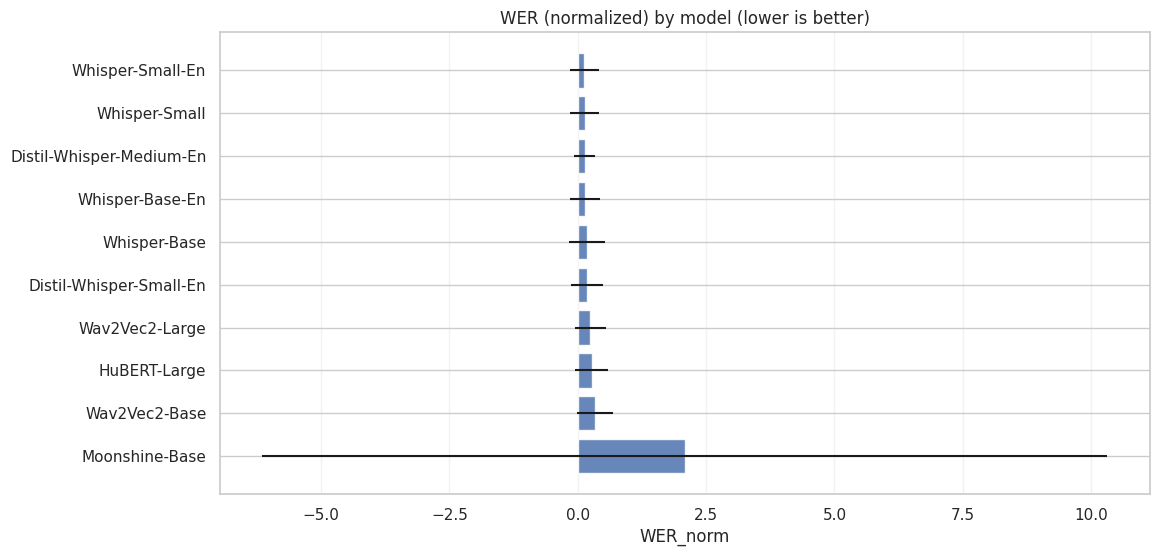

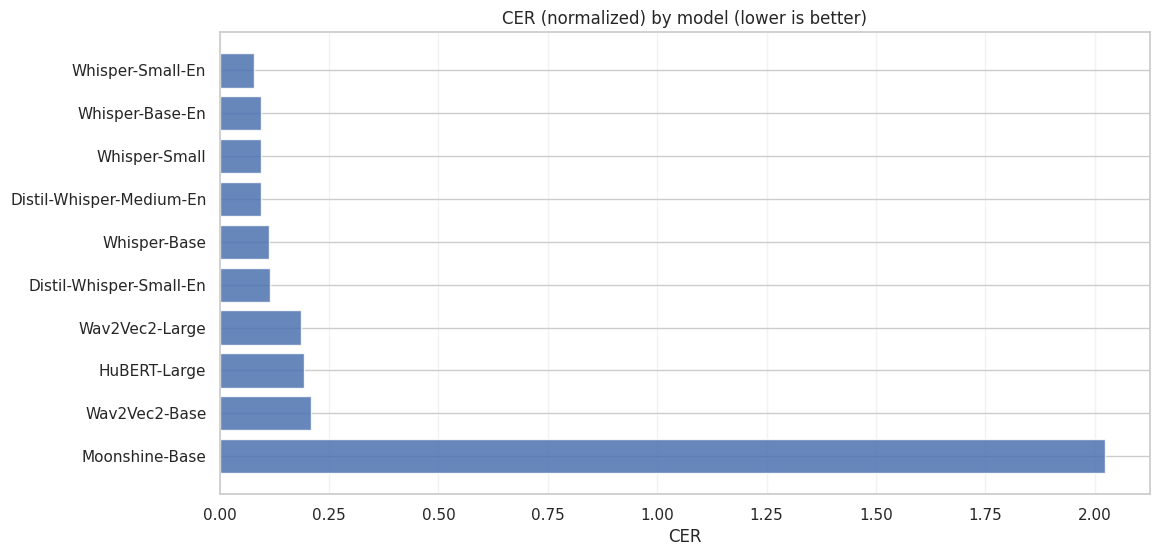

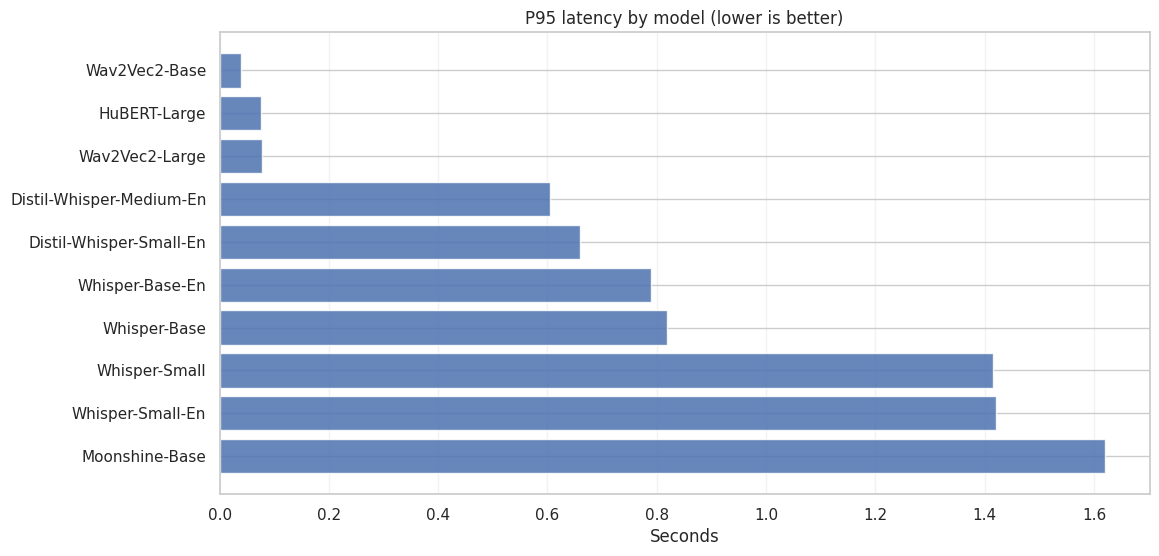

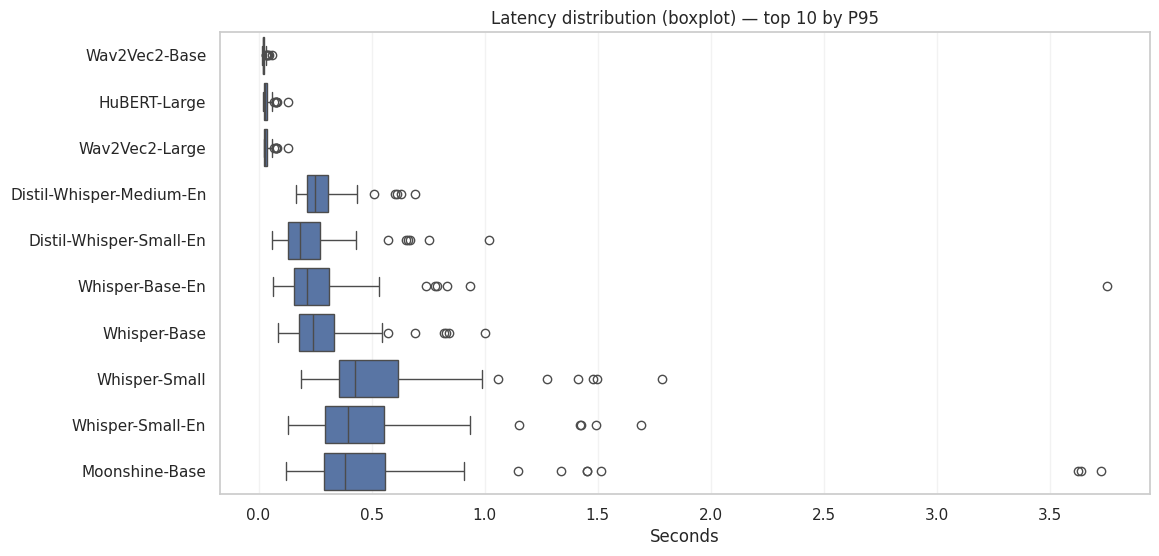

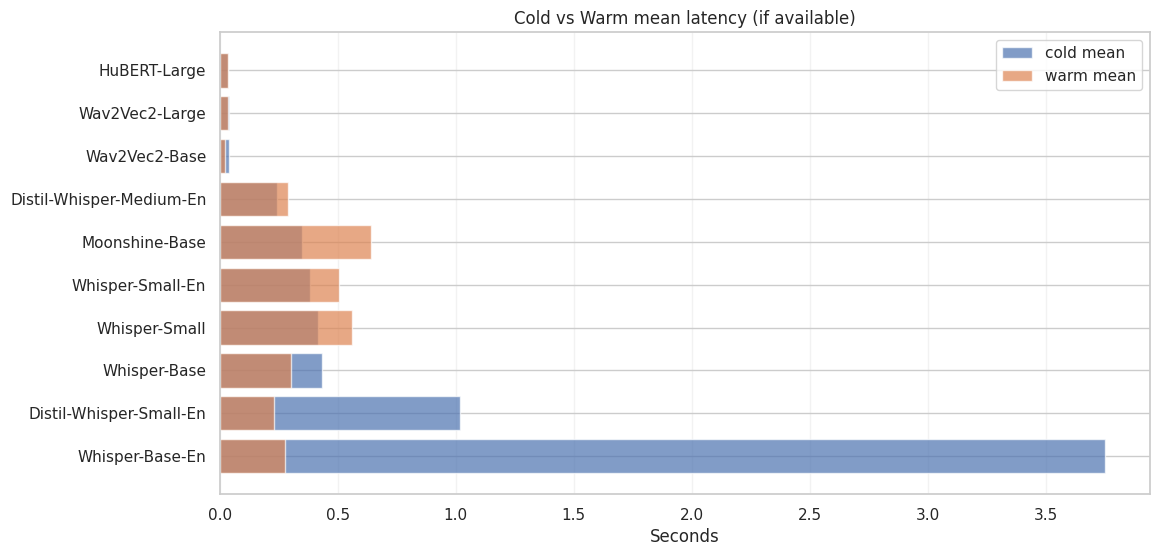

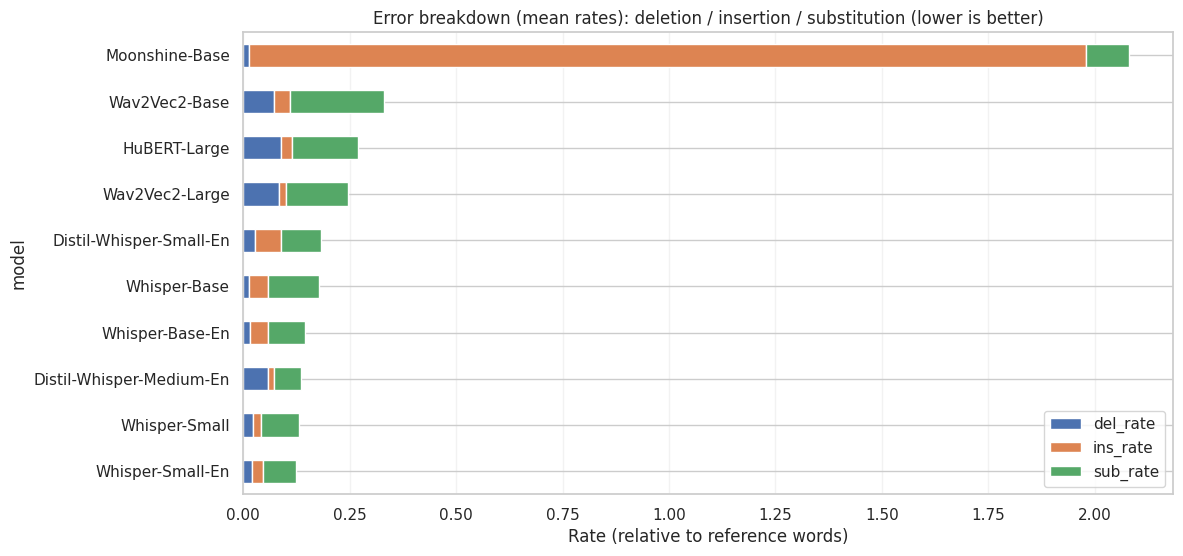

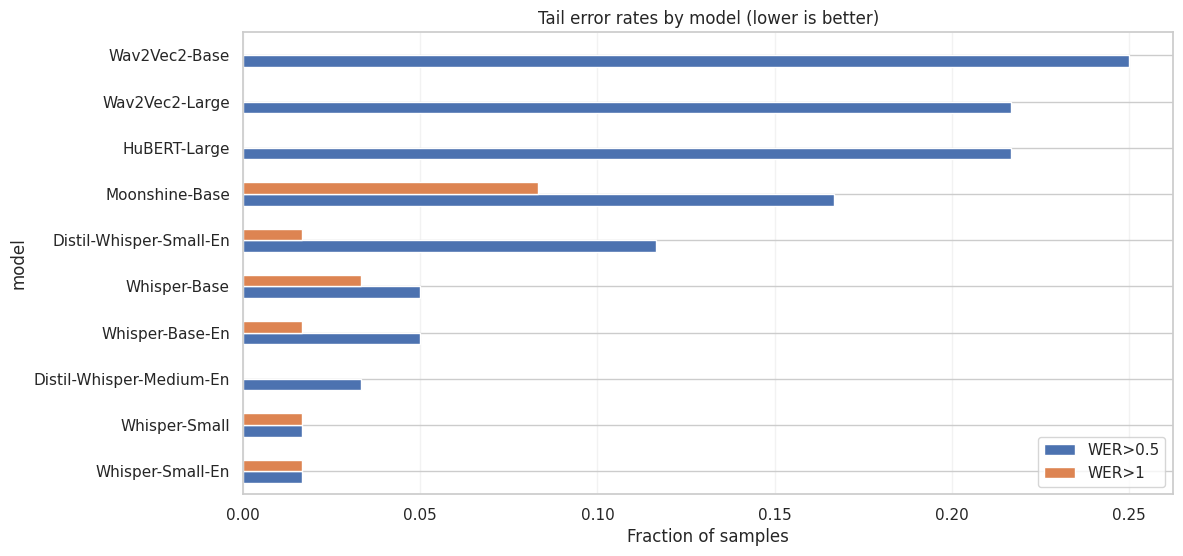

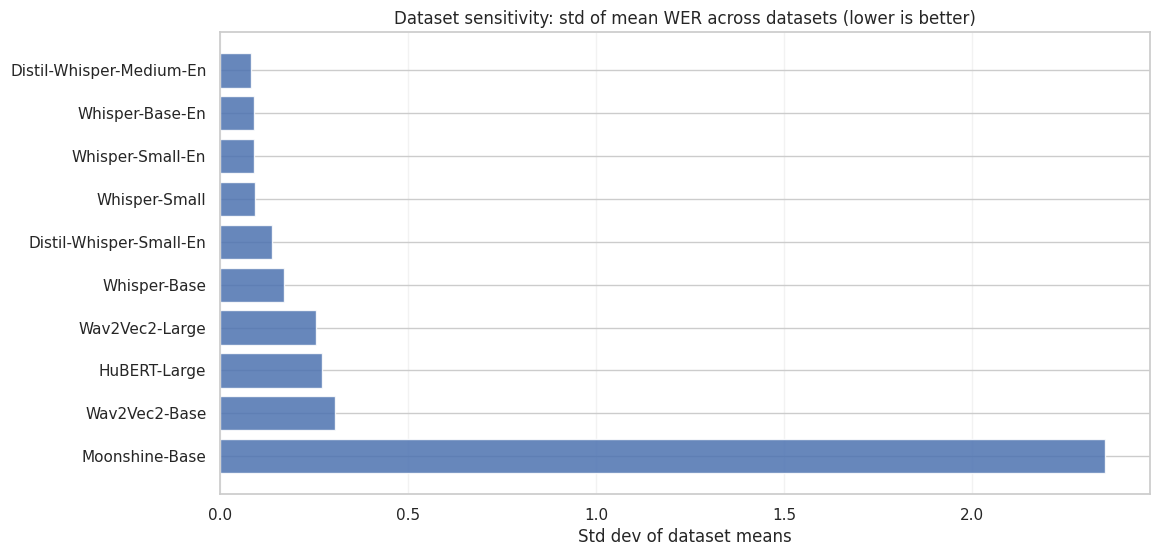

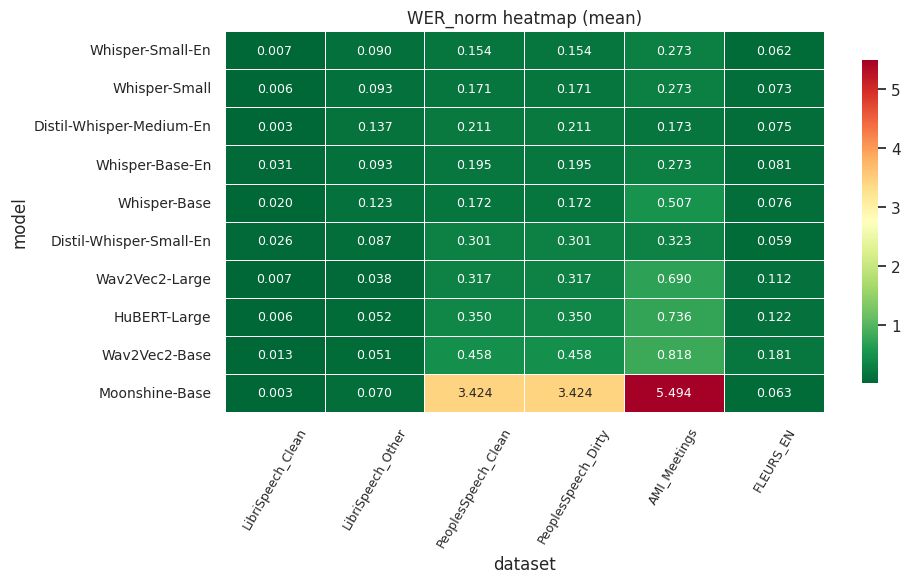

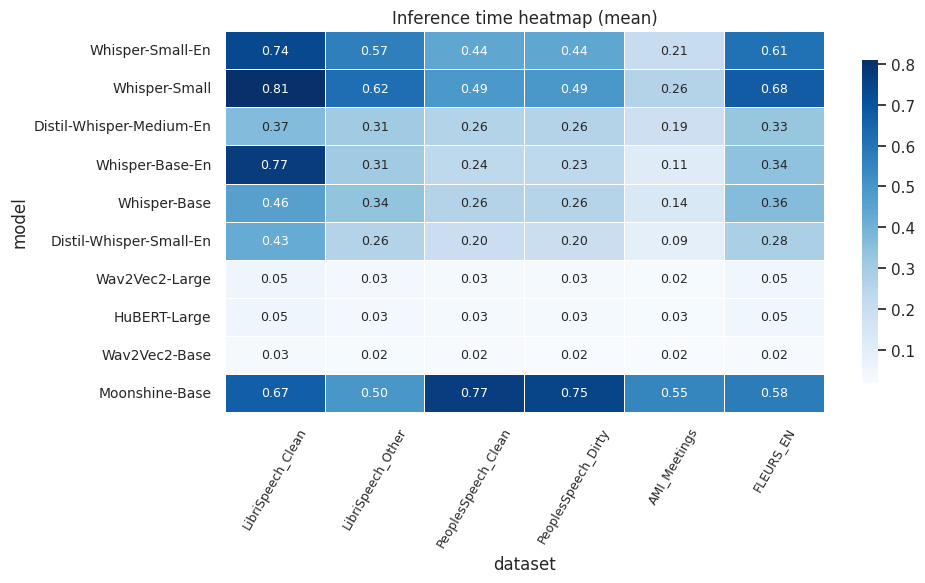

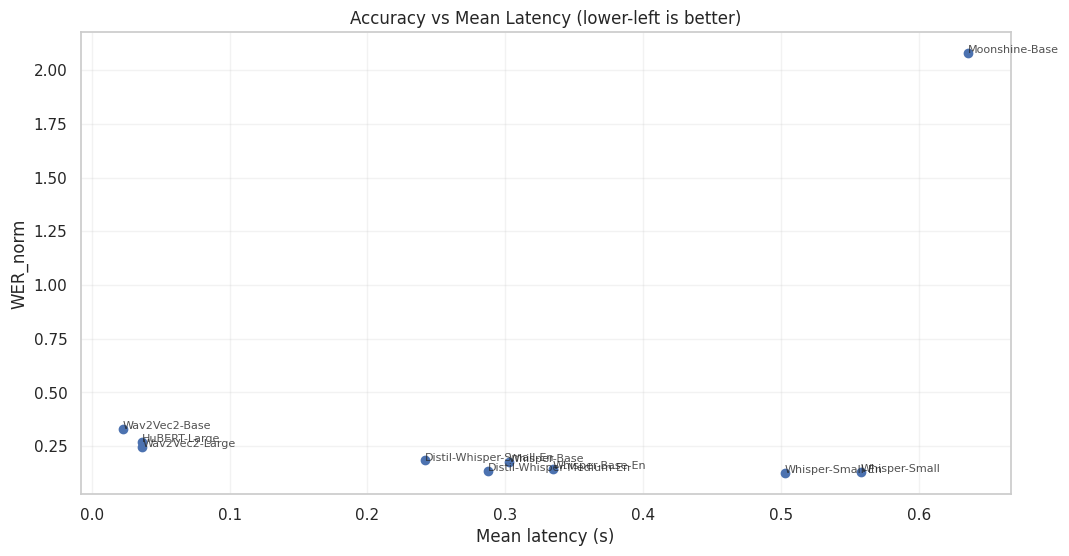

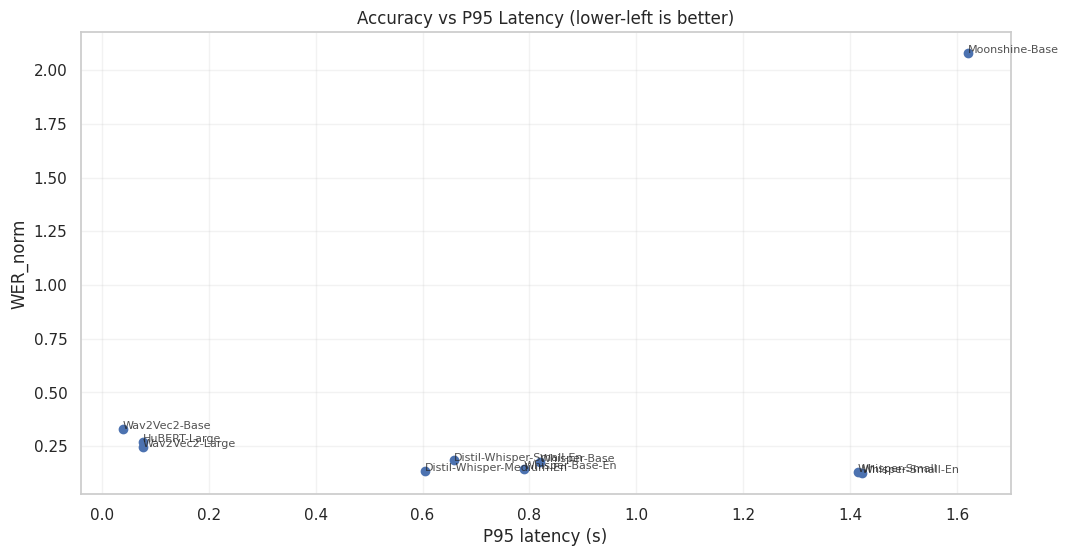

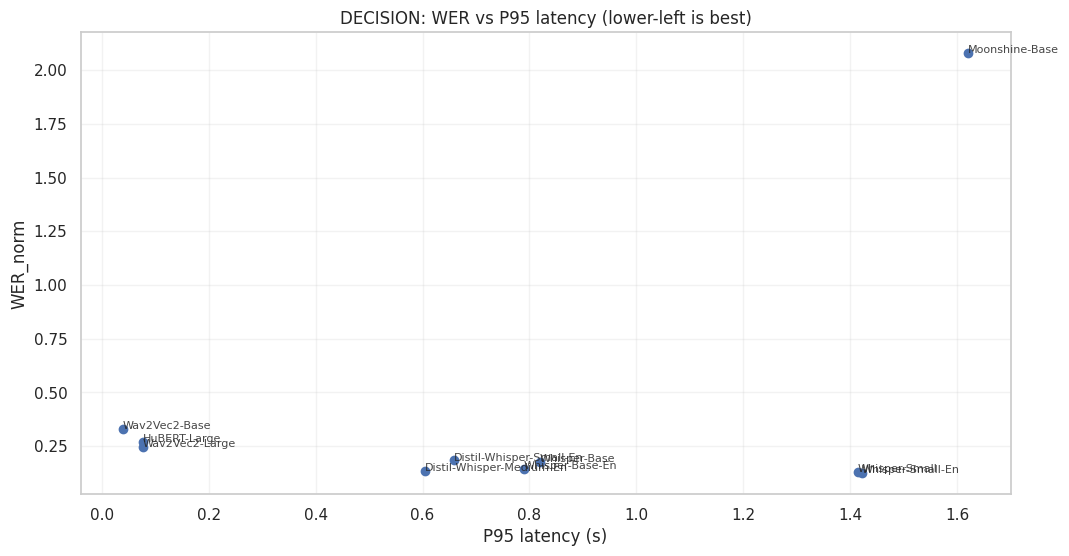

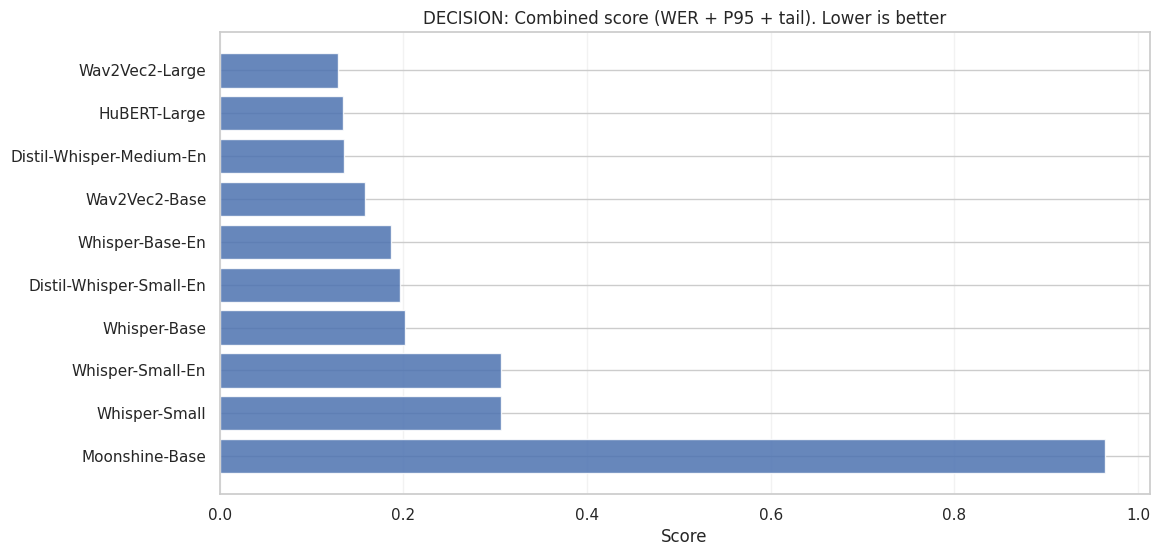

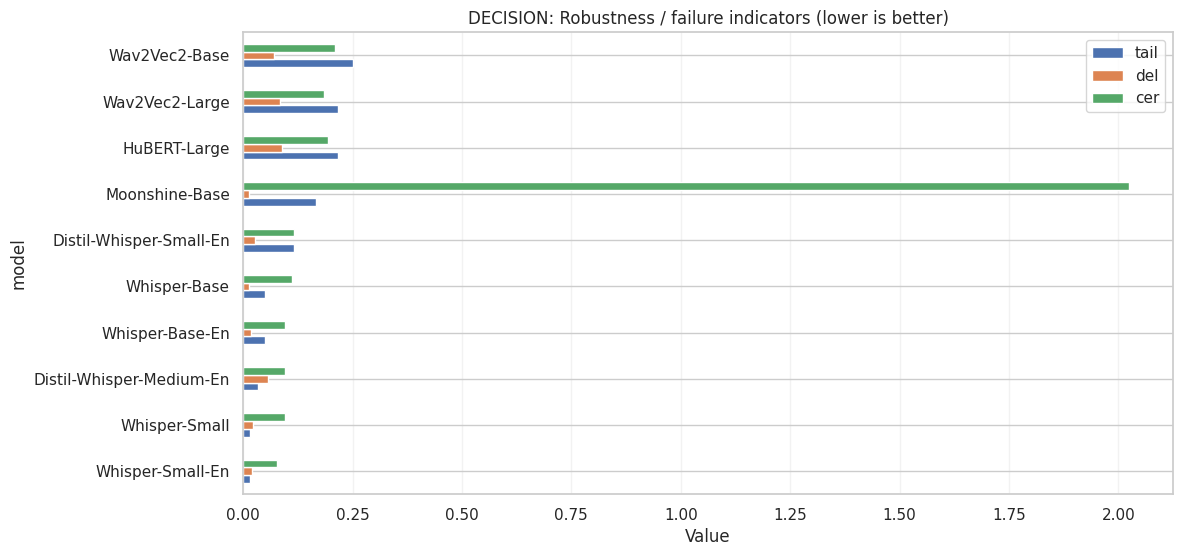

In [42]:
analyzer.display_summary_tables(df)

# Semantic categories
analyzer.plot_accuracy(df)
analyzer.plot_speed(df)
analyzer.plot_failure_modes(df)
analyzer.plot_robustness(df)
analyzer.plot_heatmaps(df)
analyzer.plot_tradeoffs(df)

# Decision plots last
analyzer.plot_decision_plots(df)

# 9. Detailed Errors Table


In [43]:
ERROR_MODEL = "ALL"        # e.g. "Whisper-Small" or "ALL"
ERROR_ROWS_LIMIT = 30      # how many rows to show
ERROR_MIN_WER = 0.20       # show only rows with wer_norm >= this (set to 0 to disable)

In [44]:
display(HTML("<h5>❌ Worst Errors (limited)</h5>"))

cols = [
    "model","dataset","language",
    "reference","transcript",
    "wer_norm","cer","time_s","peak_mem_mb",
]
existing_cols = [c for c in cols if c in df.columns]

df_err = df[existing_cols].copy()
df_err["wer_norm"] = pd.to_numeric(df_err.get("wer_norm"), errors="coerce")

# filter by model (optional)
if ERROR_MODEL != "ALL" and "model" in df_err.columns:
    df_err = df_err[df_err["model"] == ERROR_MODEL]

df_err = (
    df_err[df_err["wer_norm"].fillna(0) >= ERROR_MIN_WER]
    .sort_values("wer_norm", ascending=False)
    .head(ERROR_ROWS_LIMIT)
)

display(
    df_err.style
      .background_gradient(cmap="RdYlGn_r", subset=["wer_norm"] if "wer_norm" in df_err.columns else None)
      .format({"wer_norm": "{:.3f}", "cer": "{:.3f}", "time_s": "{:.2f}", "peak_mem_mb": "{:.1f}"}, na_rep="—")
      .set_properties(**{"white-space": "pre-wrap", "max-width": "300px"},
                      subset=[c for c in ["reference","transcript"] if c in df_err.columns])
)

,model,dataset,language,reference,transcript,wer_norm,cer,time_s,peak_mem_mb
285,Moonshine-Base,AMI_Meetings,Language.EN,YEAH YEAH,"Yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah, yeah",47.500,52.778,3.63,278.7
273,Moonshine-Base,PeoplesSpeech_Dirty,Language.EN,this is a passive house,This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This,31.400,28.435,3.62,281.8
263,Moonshine-Base,PeoplesSpeech_Clean,Language.EN,this is a passive house,This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This is a past house. This,31.400,28.435,3.73,281.8
280,Moonshine-Base,AMI_Meetings,Language.EN,YEAH,Thank you for your stuff Yeah,5.000,6.250,0.19,256.7
100,Whisper-Small-En,AMI_Meetings,Language.EN,YEAH,Thank you.,2.000,2.000,0.20,1529.6
580,Whisper-Small,AMI_Meetings,Language.EN,YEAH,Thank you.,2.000,2.000,0.28,1612.5
160,Distil-Whisper-Small-En,AMI_Meetings,Language.EN,YEAH,Thank you.,2.000,2.000,0.07,458.4
40,Whisper-Base-En,AMI_Meetings,Language.EN,YEAH,Thank you.,2.000,2.000,0.13,508.8
520,Whisper-Base,AMI_Meetings,Language.EN,YEAH,Thank you.,2.000,2.000,0.16,591.2
526,Whisper-Base,AMI_Meetings,Language.EN,MM MONDAY AFTERNOON,Und dann auf der Nähe.,1.667,0.789,0.17,591.2


# 10. Export (save CSVs)


In [45]:
os.makedirs(CONFIG.output_dir, exist_ok=True)

output_path = os.path.join(CONFIG.output_dir, "asr_results.csv")
df.to_csv(output_path, index=False)
print(f"💾 Results saved to: {output_path}")

summary_path = os.path.join(CONFIG.output_dir, "asr_summary.csv")
summary_df = df.groupby(["model", "dataset", "language"]).agg({
    "wer_norm": ["mean", "std", "min", "max"],
    "wer_raw": ["mean", "std"],
    "cer": ["mean", "std"],
    "time_s": ["mean", "std"],
    "del_rate": ["mean"],
    "ins_rate": ["mean"],
    "sub_rate": ["mean"],
}).round(4)

summary_df.to_csv(summary_path)
print(f"💾 Summary saved to: {summary_path}")

print(f"\n📁 All outputs saved to: {CONFIG.output_dir}")



💾 Results saved to: data/results/asr_results.csv
💾 Summary saved to: data/results/asr_summary.csv

📁 All outputs saved to: data/results
